# 1. Problem Definition

## Simple Concept

Problem definition means clearly deciding what the computer vision model should do, what input it will receive, and what output it must produce.

Before collecting images or building a CNN, we must understand the problem.

## Project Example: Manufacturing Defect Classification

Imagine a factory that manufactures metal components. Some components are normal, while others contain scratches or cracks.

The objective is to build an image classification model that identifies whether a component is defective or normal.

### Project Requirements

- **Input:** An image of a metal component.
- **Output:** Normal or Defective.
- **Task:** Binary image classification.
- **Model candidates:** CNN and transfer learning.
- **Evaluation:** Accuracy, precision, recall, F1-score, and confusion matrix.

## Why This Problem?

Manual inspection can take time, and small defects may be missed. An image classification model can help inspectors identify potentially defective components.

The model supports inspection; its predictions should not automatically replace necessary quality checks.

## Decision Documentation

| Decision | Reason |
|---|---|
| Manufacturing inspection | A practical computer vision application |
| Binary classification | Only two output classes are required |
| CNN | Learns useful visual features from images |
| Transfer learning | Allows us to reuse features learned by a pretrained model |
| Recall and precision | Help evaluate defect detection beyond accuracy |

## Expected Result

The trained model receives a component image and predicts whether it belongs to the Normal or Defective class.

In [1]:
# Project definition

project_name = "Manufacturing Defect Classification"

input_type = "Metal component image"

classes = ["Normal", "Defective"]

task_type = "Binary Image Classification"

print("Project:", project_name)
print("Input:", input_type)
print("Classes:", classes)
print("Task:", task_type)

Project: Manufacturing Defect Classification
Input: Metal component image
Classes: ['Normal', 'Defective']
Task: Binary Image Classification


# 2. Dataset Collection

## Simple Concept

Dataset collection means gathering images required to train and evaluate our computer vision model.

For our Manufacturing Defect Classification project, we need images belonging to two classes:

- **Normal:** Metal components without visible defects.
- **Defective:** Metal components containing defects such as scratches or cracks.

## Dataset Folder Structure

We can organize images into separate folders for training, validation, and testing.

```text
dataset/
├── train/
│   ├── Normal/
│   └── Defective/
├── val/
│   ├── Normal/
│   └── Defective/
└── test/
    ├── Normal/
    └── Defective/
```

### Purpose of Each Dataset

- **Training set:** Teaches the model to recognize patterns.
- **Validation set:** Helps compare models and tune hyperparameters.
- **Test set:** Evaluates the final model on images not used during training or tuning.

## Where Can We Get Images?

We can collect images from factory inspection systems or use a public dataset such as the MVTec Anomaly Detection dataset.

MVTec contains industrial images with normal samples and different types of defects. However, its original task and folder structure may need adaptation for our binary classification project.

## Important Decisions

| Decision | Reason |
|---|---|
| Use real or public images | Provides examples of actual visual patterns |
| Separate training, validation, and test data | Helps measure generalization fairly |
| Keep both classes represented | The model needs examples of normal and defective components |
| Avoid duplicate images across splits | Prevents misleading evaluation results |
| Preserve original images | Allows us to return to the unmodified data if needed |

## Important Note

For real industrial data, images of the same physical component or near-identical images should not be distributed across training, validation, and test sets. Otherwise, the model may appear more accurate than it really is.

Our first goal is to obtain a suitable dataset. We will validate image files and inspect class distributions in the next topics.

In [2]:
from pathlib import Path

dataset_path = Path("dataset")

splits = ["train", "val", "test"]
classes = ["Normal", "Defective"]

for split in splits:
    for class_name in classes:
        folder = dataset_path / split / class_name
        folder.mkdir(parents=True, exist_ok=True)

print("Dataset folders created successfully.")

for split in splits:
    for class_name in classes:
        folder = dataset_path / split / class_name
        print(folder)

Dataset folders created successfully.
dataset\train\Normal
dataset\train\Defective
dataset\val\Normal
dataset\val\Defective
dataset\test\Normal
dataset\test\Defective


# 3. Dataset Validation

## Simple Concept

Dataset validation means checking whether the collected images are usable before training the model.

A dataset may contain corrupted files, unsupported formats, duplicate images, incorrect folder placement, or empty class folders.

If these problems are not identified early, they can cause errors during training or reduce model performance.

## What Should We Check?

1. **Image readability:** Can Python open the image?
2. **Image format:** Is it a supported format such as JPG, JPEG, or PNG?
3. **Image dimensions:** Does the image have valid width and height?
4. **Empty folders:** Does each expected class contain images?
5. **Class labels:** Are images stored in the correct class folders?
6. **Duplicates:** Are identical or near-identical images present in multiple dataset splits?

## Decision Documentation

| Check | Why it matters |
|---|---|
| Readability | Prevents image-loading errors |
| Format | Identifies unsupported files |
| Dimensions | Detects invalid images |
| Empty classes | Identifies missing training examples |
| Labels | Prevents incorrect supervision |
| Duplicates across splits | Reduces data leakage |

## Expected Result

After validation, we should know how many images are usable, which files are invalid, and whether each class contains data.

Validation does not guarantee that every image has a correct label. Labels may also need manual inspection.

In [4]:
%pip install Pillow
from pathlib import Path
from PIL import Image

dataset_path = Path("dataset")

valid_extensions = {".jpg", ".jpeg", ".png"}

valid_count = 0
invalid_files = []

for split in ["train", "val", "test"]:
    for class_name in ["Normal", "Defective"]:

        folder = dataset_path / split / class_name

        if not folder.exists():
            print("Missing folder:", folder)
            continue

        image_files = [
            file for file in folder.iterdir()
            if file.suffix.lower() in valid_extensions
        ]

        if len(image_files) == 0:
            print("Empty class:", folder)

        for file in image_files:
            try:
                with Image.open(file) as image:
                    image.verify()

                valid_count += 1

            except Exception:
                invalid_files.append(str(file))

print("\nValid images:", valid_count)
print("Invalid images:", len(invalid_files))

for file in invalid_files:
    print("Invalid file:", file)

Note: you may need to restart the kernel to use updated packages.
Empty class: dataset\train\Normal
Empty class: dataset\train\Defective
Empty class: dataset\val\Normal
Empty class: dataset\val\Defective
Empty class: dataset\test\Normal
Empty class: dataset\test\Defective

Valid images: 0
Invalid images: 0


### Simple Concept

EDA means examining the dataset to understand its size, class distribution, image dimensions, and visual differences before training the model.

For our manufacturing defect classification project, we need to answer:

- How many Normal and Defective images are available?
- Are the classes balanced?
- Do images have different dimensions?
- Are there visible differences between normal and defective components?

**Decision:** Check class distribution and display sample images to identify data imbalance and possible data-quality issues before preprocessing.

{'Normal': 0, 'Defective': 0}


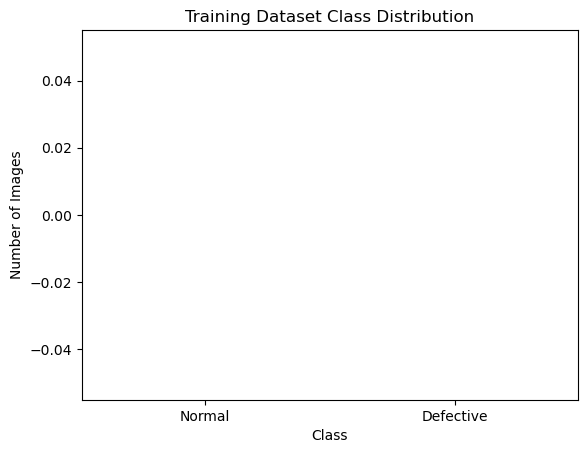

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt

dataset_path = Path("dataset/train")
classes = ["Normal", "Defective"]

counts = {
    name: sum(
        1 for file in (dataset_path / name).iterdir()
        if file.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    if (dataset_path / name).exists() else 0
    for name in classes
}

print(counts)

plt.bar(counts.keys(), counts.values())
plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

### Objective
Understand the dataset before training the object detection model.

Our screw dataset contains:
- **269 training images**
- **3,119 bounding-box annotations**
- **13 screw categories**

EDA helps us check the number of images, category distribution, and number of objects in each image.

We should identify categories with fewer annotations before training.

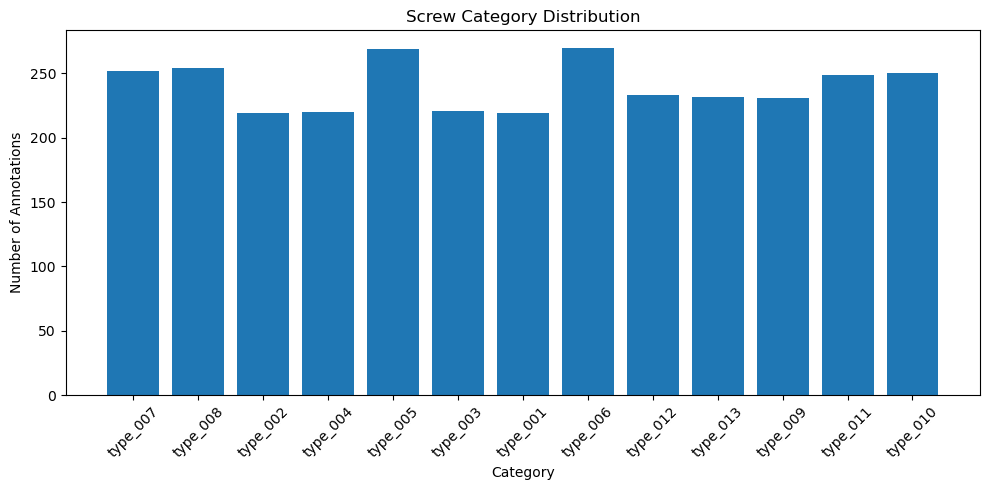

Training images: 269
Total annotations: 3119
Categories: 13
Objects per image — average: 11.59


In [17]:
import json
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

base_path = Path(
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1\v1.1"
)

with open(base_path / "mvtec_screws_train.json", "r") as f:
    data = json.load(f)

categories = {
    c["id"]: c["name"]
    for c in data["categories"]
}

# Count annotations per category
counts = Counter(
    categories[a["category_id"]]
    for a in data["annotations"]
)

plt.figure(figsize=(10, 5))
plt.bar(counts.keys(), counts.values())
plt.title("Screw Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Count objects per image
objects_per_image = Counter(
    a["image_id"] for a in data["annotations"]
)

print("Training images:", len(data["images"]))
print("Total annotations:", len(data["annotations"]))
print("Categories:", len(categories))
print("Objects per image — average:",
      round(len(data["annotations"]) / len(data["images"]), 2))

# Topic 6: Dataset Preprocessing
### Objective

Prepare screw images for the object detection model.

Our images are 1920 × 1440 pixels. We will resize them to 640 × 640 pixels to reduce computation.

**Important:** Bounding-box coordinates must be adjusted when images are resized. We will use the same scale factors for the image and its bounding boxes.

Preprocessing includes:
- Loading images.
- Converting images to RGB.
- Resizing images.
- Adjusting bounding-box coordinates.

Original size: (1920, 1440)
Resized size: (640, 640)
Scale X: 0.333
Scale Y: 0.444


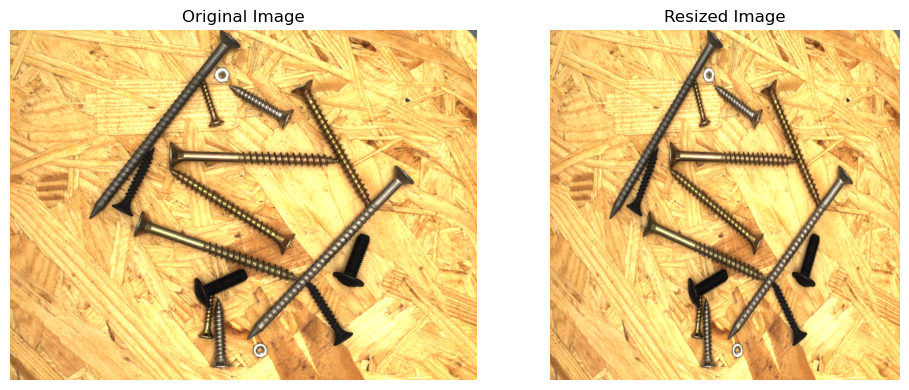

In [18]:
from PIL import Image
import matplotlib.pyplot as plt

base_path = r"C:\Users\nanda\Downloads\mvtec_screws_v1.1\v1.1"
image_path = base_path + r"\images\screws_002.png"

image = Image.open(image_path).convert("RGB")

original_width, original_height = image.size
new_size = (640, 640)

resized_image = image.resize(new_size)

scale_x = new_size[0] / original_width
scale_y = new_size[1] / original_height

print("Original size:", image.size)
print("Resized size:", resized_image.size)
print("Scale X:", round(scale_x, 3))
print("Scale Y:", round(scale_y, 3))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image)
plt.title("Resized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Topic 7: Bounding Box Preprocessing
### Objective

When an image is resized, its bounding boxes must also be resized.

A bounding box contains:
- **X:** horizontal position
- **Y:** vertical position
- **Width:** box width
- **Height:** box height

We multiply X and width by the horizontal scale factor, and Y and height by the vertical scale factor. This keeps each bounding box aligned with its object.

In [19]:
import json
from pathlib import Path
from PIL import Image

base_path = Path(
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1\v1.1"
)

with open(base_path / "mvtec_screws_train.json", "r") as f:
    data = json.load(f)

image_info = data["images"][0]
image_path = base_path / "images" / image_info["file_name"]

image = Image.open(image_path).convert("RGB")

original_width, original_height = image.size
new_width, new_height = 640, 640

scale_x = new_width / original_width
scale_y = new_height / original_height

resized_boxes = []

for ann in data["annotations"]:
    if ann["image_id"] == image_info["id"]:
        x, y, width, height = ann["bbox"][:4]

        resized_boxes.append([
            x * scale_x,
            y * scale_y,
            width * scale_x,
            height * scale_y
        ])

print("Image:", image_info["file_name"])
print("Original image size:", image.size)
print("Resized image size:", (new_width, new_height))
print("Number of bounding boxes:", len(resized_boxes))
print("First resized box:", resized_boxes[0] if resized_boxes else "None")

Image: screws_002.png
Original image size: (1920, 1440)
Resized image size: (640, 640)
Number of bounding boxes: 16
First resized box: [61.8, 387.7622222222222, 21.333333333333332, 27.80582222222222]


# Topic 8: Data Augmentation
### Objective

Data augmentation creates modified versions of training images to help an object detection model learn from different variations.

Common techniques include:
- Horizontal flipping
- Brightness adjustment
- Small rotations

**Important:** When an image is augmented, its bounding boxes must be transformed accordingly. We should apply augmentation only to training data, not validation or test data.

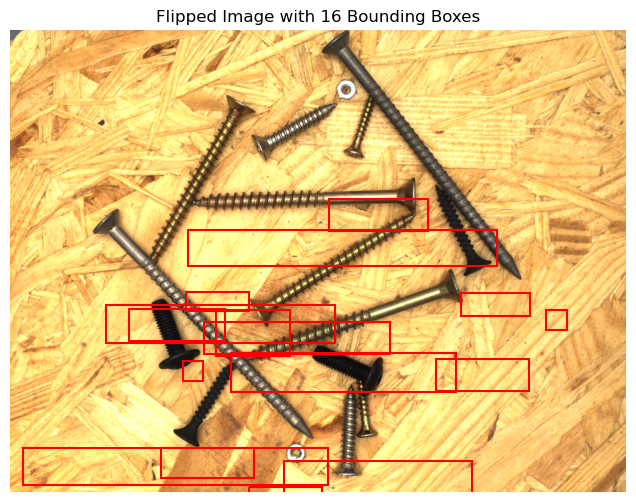

In [20]:
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

base_path = Path(
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1\v1.1"
)

with open(base_path / "mvtec_screws_train.json", "r") as f:
    data = json.load(f)

image_info = data["images"][0]
image = Image.open(
    base_path / "images" / image_info["file_name"]
).convert("RGB")

image_width, image_height = image.size
flipped_image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(flipped_image)

box_count = 0

for ann in data["annotations"]:
    if ann["image_id"] == image_info["id"]:
        x, y, w, h = ann["bbox"][:4]

        # Update bounding box after horizontal flip
        flipped_x = image_width - (x + w)

        rect = patches.Rectangle(
            (flipped_x, y), w, h,
            linewidth=1.5,
            edgecolor="red",
            facecolor="none"
        )
        ax.add_patch(rect)
        box_count += 1

ax.set_title(f"Flipped Image with {box_count} Bounding Boxes")
ax.axis("off")
plt.show()

# Topic 9: Prepare Train, Validation, and Test Sets
### Objective

Our dataset already provides separate JSON annotation files for training, validation, and testing.

- **Training:** Used to teach the model.
- **Validation:** Used to compare models and tune settings.
- **Testing:** Used for final evaluation.

We should preserve these existing splits instead of randomly splitting the images again. This helps avoid data leakage.

Before training, we will verify the image and annotation counts in all three sets.

In [21]:
import json
from pathlib import Path

base_path = Path(
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1\v1.1"
)

for split in ["train", "val", "test"]:
    json_path = base_path / f"mvtec_screws_{split}.json"

    with open(json_path, "r") as f:
        data = json.load(f)

    print(f"\n{split.upper()} SET")
    print("Images:", len(data["images"]))
    print("Annotations:", len(data["annotations"]))

    image_names = {img["file_name"] for img in data["images"]}

    missing = [
        name for name in image_names
        if not (base_path / "images" / name).exists()
    ]

    print("Missing images:", len(missing))


TRAIN SET
Images: 269
Annotations: 3119
Missing images: 0

VAL SET
Images: 55
Annotations: 647
Missing images: 0

TEST SET
Images: 60
Annotations: 661
Missing images: 0


# Topic 10: Baseline Object Detection Model
### Objective

Build a simple baseline object detection model to establish a starting point for our screw dataset.

We have 13 screw categories and bounding-box annotations. A detection model must predict both:
- **Class:** Which screw category is present.
- **Bounding box:** Where the screw is located.

We will use a pretrained Faster R-CNN model from TorchVision as our starting point. It can detect multiple objects in an image and predict their classes and bounding boxes.

In [23]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("TorchVision version:", torchvision.__version__)

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn(weights=weights)

model.eval()

print("Baseline model loaded successfully.")

PyTorch version: 2.14.0+cpu
TorchVision version: 0.29.1+cpu
Baseline model loaded successfully.


Important: This loads a model pretrained on COCO, not your 13 screw categories. Before training, we must replace its classification head and prepare your dataset in the format expected by Faster R-CNN.

# Topic 8: CNN for Computer Vision
### Objective

A Convolutional Neural Network (CNN) learns visual features from images, such as edges, shapes, textures, and object parts.

In our screw object-detection project, CNN features help the model recognize screw patterns. Faster R-CNN uses a CNN backbone to extract these features, then predicts object categories and bounding boxes.

**Workflow:**

Input image → CNN feature extraction → Region proposals → Classification and bounding-box prediction.

We are using a pretrained ResNet-50 backbone in Faster R-CNN, so we do not need to build a separate CNN from scratch for this project.

In [25]:
# Inspect the feature extraction backbone
print(model.backbone)

# Check the model's detection components
print("\nRegion proposal network:")
print(model.rpn)

print("\nObject classification and bounding-box head:")
print(model.roi_heads.box_predictor)

BackboneWithFPN(
  (body): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): FrozenBatchNorm2d(64, eps=0.0)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): FrozenBatchNorm2d(64, eps=0.0)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): FrozenBatchNorm2d(64, eps=0.0)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): FrozenBatchNorm2d(256, eps=0.0)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): FrozenBatchNorm2d(256, eps=0.0)
        )
      )
      (1): Bottleneck(
        (conv1): C

# Topic 9: Transfer Learning
### Objective

Transfer learning uses a model that has already learned useful image features from a large dataset.

In our screw detection project, Faster R-CNN is pretrained on COCO. We replace its prediction head to support our 13 screw categories.

Initially, the model retains its pretrained feature-extraction weights. Training on our screw dataset then adapts the model to the new categories.

**Benefits:** Less training from scratch and a useful starting point when our dataset is relatively small.

In [26]:
# Freeze the backbone
for param in model.backbone.parameters():
    param.requires_grad = False

# Train only the detection components
for param in model.rpn.parameters():
    param.requires_grad = True

for param in model.roi_heads.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)
print("Backbone frozen:", all(
    not p.requires_grad for p in model.backbone.parameters()
))

Trainable parameters: 14561365
Backbone frozen: True


# Topic 10: Hyperparameter Experiments
### Objective

Hyperparameters are settings we choose before training the model.

For our Faster R-CNN screw detection project, important hyperparameters include:

- **Learning rate:** Controls how much model weights change during training.
- **Batch size:** Number of images processed together.
- **Number of epochs:** Number of complete passes through the training dataset.

We will compare different learning rates while keeping other settings fixed. We should use validation performance to select the best setting.

In [27]:
import torch

learning_rates = [0.001, 0.0001, 0.00001]

for lr in learning_rates:
    optimizer = torch.optim.SGD(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        momentum=0.9,
        weight_decay=0.0005
    )

    print("Learning rate:", lr)
    print("Optimizer:", type(optimizer).__name__)

Learning rate: 0.001
Optimizer: SGD
Learning rate: 0.0001
Optimizer: SGD
Learning rate: 1e-05
Optimizer: SGD


# Topic 11: Model Evaluation

## Objective

Model evaluation measures how well our Faster R-CNN model detects and classifies screws.

We will evaluate the model using the validation dataset during development and the test dataset for final evaluation.

Important evaluation metrics:

- **IoU (Intersection over Union):** Measures how closely a predicted bounding box matches the actual bounding box.
- **Precision:** Measures how many predicted detections are correct.
- **Recall:** Measures how many actual objects the model successfully detects.
- **mAP (mean Average Precision):** Summarizes detection performance across categories and confidence thresholds.

A good model should detect screw objects, predict the correct categories, and produce accurate bounding boxes.

We should compare these metrics across experiments rather than relying only on classification accuracy.

Predicted boxes: torch.Size([100, 4])
Predicted labels: [2, 2, 2, 4, 2, 2, 2, 2, 2, 2]
Confidence scores: [0.2617170214653015, 0.26094257831573486, 0.2507384717464447, 0.24624362587928772, 0.24509437382221222, 0.24314047396183014, 0.24088013172149658, 0.23559635877609253, 0.23529139161109924, 0.23403340578079224]


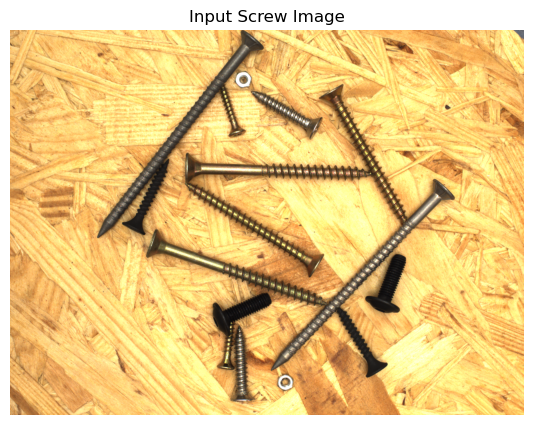

In [28]:
import torch
import matplotlib.pyplot as plt
from torchvision.transforms.functional import to_tensor
from PIL import Image

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

image_path = (
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1"
    r"\v1.1\images\screws_002.png"
)

image = Image.open(image_path).convert("RGB")
image_tensor = to_tensor(image).to(device)

with torch.no_grad():
    prediction = model([image_tensor])[0]

print("Predicted boxes:", prediction["boxes"].shape)
print("Predicted labels:", prediction["labels"][:10].cpu().tolist())
print("Confidence scores:", prediction["scores"][:10].cpu().tolist())

plt.figure(figsize=(8, 5))
plt.imshow(image)
plt.title("Input Screw Image")
plt.axis("off")
plt.show()

# Topic 12: Model Error Analysis

## Objective

Error analysis helps us understand why our screw detection model makes incorrect predictions.

We will investigate these common errors:

- **Missed detection:** A screw is present, but the model does not detect it.
- **Incorrect classification:** The model detects a screw but predicts the wrong category.
- **Poor bounding box:** The predicted box does not align well with the actual screw.
- **False positive:** The model predicts an object where no matching object exists.
- **Low confidence:** The model is uncertain about its prediction.

By reviewing these errors, we can identify areas for improvement, such as collecting more training images, adjusting confidence thresholds, or fine-tuning the model.

We should perform this analysis using predictions from a trained model, not an untrained model.

In [30]:
import json
import torch
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms.functional import to_tensor

base_path = Path(
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1\v1.1"
)

class ScrewDataset(Dataset):
    def __init__(self, split):
        with open(base_path / f"mvtec_screws_{split}.json", "r") as f:
            data = json.load(f)

        self.images = data["images"]
        self.image_dir = base_path / "images"
        self.annotations = {}

        for ann in data["annotations"]:
            self.annotations.setdefault(
                ann["image_id"], []
            ).append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        info = self.images[index]

        image = Image.open(
            self.image_dir / info["file_name"]
        ).convert("RGB")

        boxes, labels = [], []

        for ann in self.annotations.get(info["id"], []):
            x, y, w, h = ann["bbox"][:4]
            boxes.append([x, y, x + w, y + h])
            labels.append(ann["category_id"])

        target = {
            "boxes": torch.tensor(
                boxes, dtype=torch.float32
            ).reshape(-1, 4),
            "labels": torch.tensor(
                labels, dtype=torch.int64
            )
        }

        return to_tensor(image), target

train_dataset = ScrewDataset("train")

print("Training images:", len(train_dataset))

Training images: 269


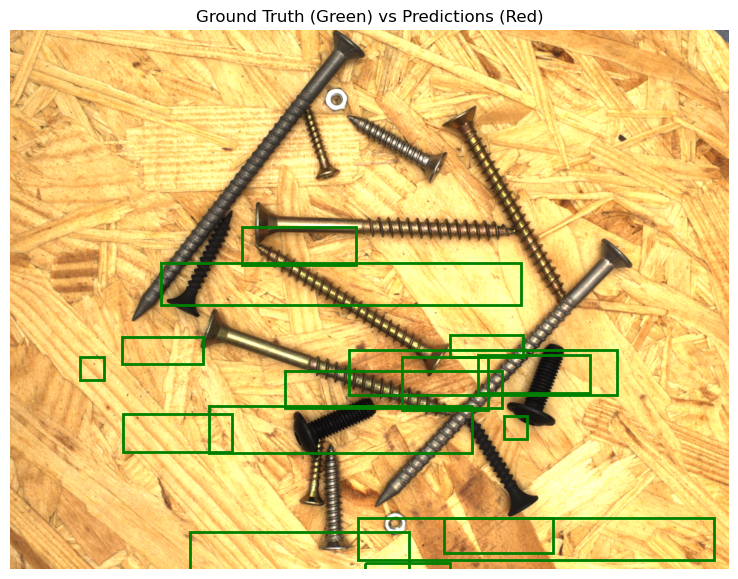

In [31]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch

# Get one image and its ground-truth annotations
image_tensor, target = train_dataset[0]

model.eval()

with torch.no_grad():
    prediction = model([image_tensor.to(device)])[0]

image = image_tensor.permute(1, 2, 0).cpu().numpy()

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)

# Ground-truth boxes in green
for box in target["boxes"].numpy():
    x1, y1, x2, y2 = box
    ax.add_patch(
        patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            edgecolor="green", facecolor="none",
            linewidth=2
        )
    )

# Predictions in red, filtered by confidence
for box, score in zip(
    prediction["boxes"].cpu().numpy(),
    prediction["scores"].cpu().numpy()
):
    if score < 0.5:
        continue

    x1, y1, x2, y2 = box
    ax.add_patch(
        patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            edgecolor="red", facecolor="none",
            linewidth=1.5
        )
    )

ax.set_title("Ground Truth (Green) vs Predictions (Red)")
ax.axis("off")
plt.show()

# Topic 13: Model Explainability

## Objective

Model explainability helps us understand why an object detection model makes a prediction.

In our screw detection project, we want to understand which image regions contribute to detecting a screw and predicting its category.

Common techniques include:

- **Feature maps:** Show visual features extracted by CNN layers.
- **Grad-CAM:** Highlights image regions that influence a model's prediction.
- **Confidence scores:** Indicate how confident the model is about a predicted detection.

Explainability can help us identify whether the model focuses on the screw itself or irrelevant background details.

**Important:** Explainability results are easier to interpret after the model has been trained and produces meaningful screw detections.

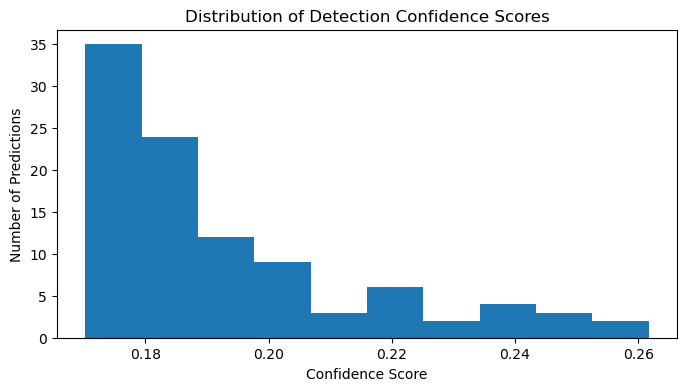

Total predictions: 100


In [32]:
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.transforms.functional import to_tensor

image_path = (
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1"
    r"\v1.1\images\screws_002.png"
)

image = Image.open(image_path).convert("RGB")
image_tensor = to_tensor(image).to(device)

model.eval()

with torch.no_grad():
    prediction = model([image_tensor])[0]

scores = prediction["scores"].cpu().numpy()

plt.figure(figsize=(8, 4))
plt.hist(scores, bins=10)
plt.title("Distribution of Detection Confidence Scores")
plt.xlabel("Confidence Score")
plt.ylabel("Number of Predictions")
plt.show()

print("Total predictions:", len(scores))

# Topic 14: Model Optimization

## Objective

Model optimization improves detection performance, training speed, or memory usage.

For our Faster R-CNN screw detection project, we can try:

- **Learning-rate tuning:** Find a suitable learning rate.
- **Backbone freezing:** Reduce the number of trainable parameters.
- **Batch-size adjustment:** Manage memory usage.
- **Confidence threshold tuning:** Filter low-confidence detections.
- **Image-size adjustment:** Balance detection quality and computation time.

We should change one setting at a time and compare validation results. Optimization should improve the model without compromising detection quality.

In [33]:
import torch

model.eval()

with torch.no_grad():
    prediction = model([image_tensor])[0]

confidence_threshold = 0.5

keep = prediction["scores"] >= confidence_threshold

filtered_boxes = prediction["boxes"][keep]
filtered_labels = prediction["labels"][keep]
filtered_scores = prediction["scores"][keep]

print("Detections before filtering:", len(prediction["scores"]))
print("Detections after filtering:", len(filtered_scores))

Detections before filtering: 100
Detections after filtering: 0


# Topic 15: Final Model

## Objective

Select and save the best-performing Faster R-CNN model for our screw object-detection project.

The final model should be selected based on validation performance, including:

- **mAP:** Overall object-detection performance across categories.
- **Precision and recall:** Correct detections and missed objects.
- **Inference speed:** Time required to process an image.

After selecting the best model, save its trained weights and configuration. The model should be evaluated on the test dataset before reporting final results.

**Important:** Saving a model does not train it. Save the model only after training and selecting the best checkpoint.

In [34]:
import torch
from pathlib import Path

save_path = Path("screw_detection_model.pth")

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "num_classes": 14,
        "class_names": [
            "background",
            "type_001", "type_002", "type_003",
            "type_004", "type_005", "type_006",
            "type_007", "type_008", "type_009",
            "type_010", "type_011", "type_012",
            "type_013"
        ]
    },
    save_path
)

print("Model saved to:", save_path.resolve())

Model saved to: C:\Users\nanda\Sprint -10\screw_detection_model.pth


# Topic 16: Inference

**Inference** means using a trained model to make predictions on a new image that the model has not seen during training.

For our screw detection project, inference identifies screw types and predicts their bounding boxes.

**Inference workflow:**

1. Load the trained model.
2. Load a new screw image.
3. Convert the image into a tensor.
4. Pass the image to the model.
5. Get predicted bounding boxes, class labels, and confidence scores.
6. Display detections above the confidence threshold.

**Important:** Our model must be trained before its predictions can be trusted. Saving an untrained model does not make it ready for real predictions.

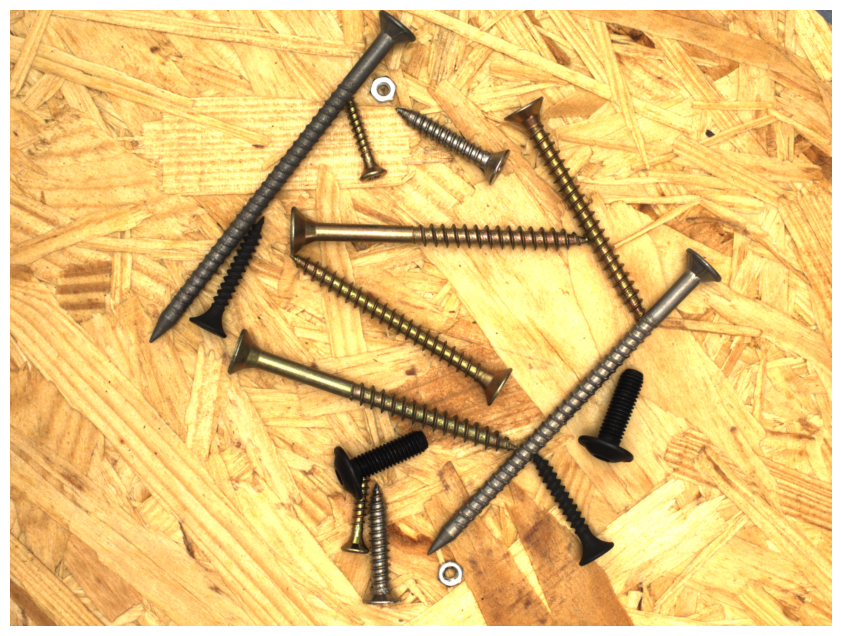

In [35]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image
from torchvision.transforms.functional import to_tensor
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# Paths
base_path = Path(
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1\v1.1"
)
checkpoint_path = Path("screw_detection_model.pth")
image_path = base_path / "images" / "screws_002.png"

# Class names
class_names = [
    "background",
    "type_001", "type_002", "type_003",
    "type_004", "type_005", "type_006",
    "type_007", "type_008", "type_009",
    "type_010", "type_011", "type_012",
    "type_013"
]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Recreate the model architecture
model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None
)

in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features, 14
)

# Load trained weights
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

# Load image
image = Image.open(image_path).convert("RGB")
image_tensor = to_tensor(image).to(device)

# Make predictions
with torch.no_grad():
    prediction = model([image_tensor])[0]

# Display detections
threshold = 0.5
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

for box, label, score in zip(
    prediction["boxes"],
    prediction["labels"],
    prediction["scores"]
):
    if score.item() < threshold:
        continue

    x1, y1, x2, y2 = box.cpu().tolist()

    rectangle = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(rectangle)

    ax.text(
        x1, y1,
        f"{class_names[label.item()]}: {score.item():.2f}",
        color="black",
        backgroundcolor="lime"
    )

ax.axis("off")
plt.show()

# Topic 17: Document Decisions

**Documenting decisions** means recording the important choices made during the screw detection project and explaining why they were made.

This helps others understand, reproduce, and maintain the project.

### Decisions to Document

| Area | Decision |
|---|---|
| Dataset | MVTec Screws dataset |
| Task | Detect screws and classify their types |
| Annotation | COCO-style JSON files with bounding boxes |
| Data split | Use the provided train, validation, and test sets |
| Model | Faster R-CNN with ResNet-50 FPN |
| Transfer learning | Start with pretrained weights and adapt the detection head |
| Evaluation | Measure detection quality using IoU and mAP |
| Confidence threshold | Start with 0.5 and adjust based on validation results |
| Final model | Save the best model checkpoint after training and evaluation |

### What to Record

- Why the model was selected.
- What preprocessing and augmentation were applied.
- Which hyperparameters were tested.
- How the model was evaluated.
- What errors were found and how they were addressed.
- Known limitations and possible improvements.

**Important:** These are the current project decisions, not proof of successful training. Record actual evaluation results only after running the experiments.

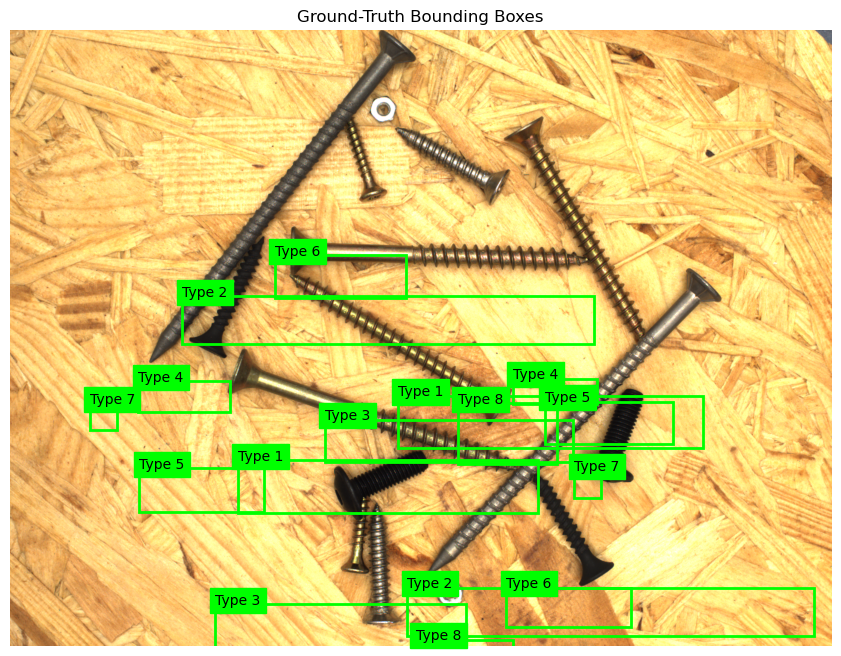

In [36]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image_tensor, target = train_dataset[0]
image = image_tensor.permute(1, 2, 0).numpy()

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

for box, label in zip(target["boxes"], target["labels"]):
    x1, y1, x2, y2 = box.tolist()

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(rect)

    ax.text(x1, y1, f"Type {label.item()}",
            color="black", backgroundcolor="lime")

ax.set_title("Ground-Truth Bounding Boxes")
ax.axis("off")
plt.show()

In [37]:
import json
from pathlib import Path

base_path = Path(
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1\v1.1"
)

with open(base_path / "mvtec_screws_train.json", "r") as f:
    data = json.load(f)

print("Image information:")
print(data["images"][0])

print("\nOriginal annotation:")
print(data["annotations"][0])

Image information:
{'file_name': 'screws_002.png', 'height': 1440, 'width': 1920, 'id': 1, 'license': 1}

Original annotation:
{'area': 4004.04, 'bbox': [185.4, 872.465, 64, 62.5631, 0], 'category_id': 7, 'id': 1001, 'image_id': 1, 'is_crowd': 0}


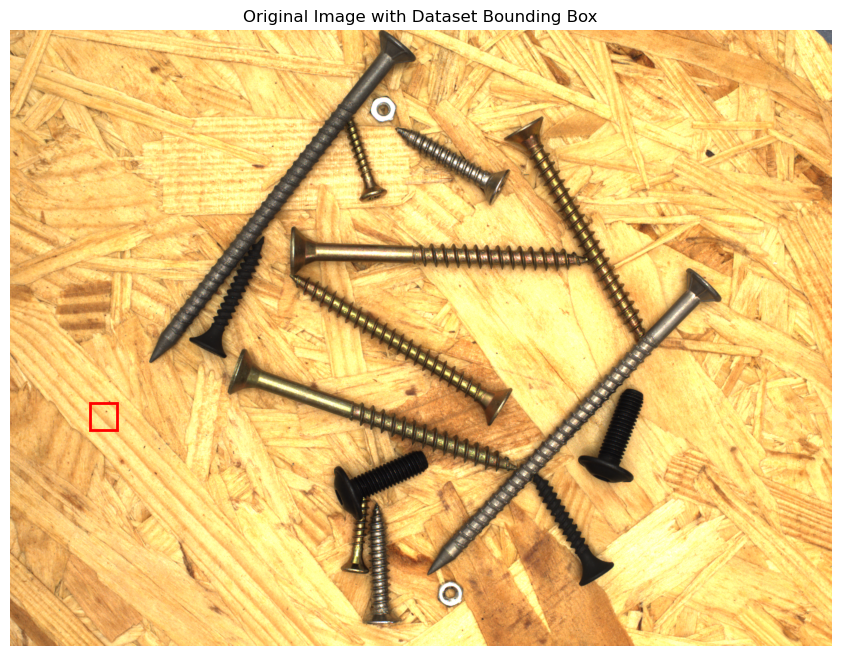

Image size: (1920, 1440)
Bounding box: [185.4, 872.465, 64, 62.5631, 0]


In [38]:
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

base_path = Path(
    r"C:\Users\nanda\Downloads\mvtec_screws_v1.1\v1.1"
)

with open(base_path / "mvtec_screws_train.json", "r") as f:
    data = json.load(f)

image_info = data["images"][0]
annotation = next(
    a for a in data["annotations"]
    if a["image_id"] == image_info["id"]
)

image_path = base_path / "images" / image_info["file_name"]
image = Image.open(image_path).convert("RGB")

x, y, w, h = annotation["bbox"][:4]

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

rect = patches.Rectangle(
    (x, y), w, h,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)
ax.add_patch(rect)

ax.set_title("Original Image with Dataset Bounding Box")
ax.axis("off")
plt.show()

print("Image size:", image.size)
print("Bounding box:", annotation["bbox"])

In [39]:
print(data["info"])
print(data["categories"][:3])
print(data["annotations"][:3])

{'contributor': 'MVTec Software GmbH', 'date_created': '2026-1-14', 'description': 'This is the MVTec Screws dataset in a COCO-like format.', 'url': 'https://www.mvtec.com/research', 'version': '1.1', 'year': 2026}
[{'id': 1, 'name': 'type_001', 'supercategory': 'object'}, {'id': 2, 'name': 'type_002', 'supercategory': 'object'}, {'id': 3, 'name': 'type_003', 'supercategory': 'object'}]
[{'area': 4004.04, 'bbox': [185.4, 872.465, 64, 62.5631, 0], 'category_id': 7, 'id': 1001, 'image_id': 1, 'is_crowd': 0}, {'area': 3891.43, 'bbox': [1318.5, 1030.22, 62.2, 62.5631, 0], 'category_id': 7, 'id': 1002, 'image_id': 1, 'is_crowd': 0}, {'area': 32207.2, 'bbox': [947.7, 1424.61, 227.25, 141.726, 1.207281], 'category_id': 8, 'id': 1003, 'image_id': 1, 'is_crowd': 0}]
